# LASV proteome seroreactivity and Mammarenavirus cross-reactivity analysis


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices

# ---------- paths ----------
LONG_FILE = Path('./output_files/long_spec_0_98_111226.csv')
OUTDIR = Path('./output_figures')
OUTDIR.mkdir(parents=True, exist_ok=True)

# ---------- publication style ----------
plt.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'legend.fontsize': 9.5,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})

CATEGORY_ORDER = ['Household contact', 'Lassa survivor', 'US healthy']
CATEGORY_COLORS = {
    'Household contact': '#0072B2',  # blue
    'Lassa survivor': '#D55E00',     # vermillion
    'US healthy': '#009E73',         # bluish green
}

## 1. Load LASV peptide-level data and Josiah references

In [15]:
pep_long = pd.read_csv(LONG_FILE)
lassa = pep_long.loc[pep_long['species'].eq('Mammarenavirus lassaense')].copy()
print('LASV rows:', len(lassa))
print('LASV peptides:', lassa['peptide'].nunique())


LASV rows: 119064
LASV peptides: 246


## 2. Make matrix showing max z score for each protein across the cohort

In [75]:
lassa_max_per_protein = lassa.groupby(['protein_std', 'individual'])['z_score'].max().reset_index()

In [76]:
lassa_max_wide = lassa_max_per_protein.pivot_table(values='z_score', index='protein_std', columns='individual')


In [77]:
c_cols = lassa_max_wide.filter(regex='C-').columns
s_cols = lassa_max_wide.filter(regex='S-').columns
hbdb_cols = lassa_max_wide.filter(regex='HBDB').columns

In [78]:
lassa_max_wide = lassa_max_wide.loc[:, list(c_cols) + list(s_cols) + list(hbdb_cols)]

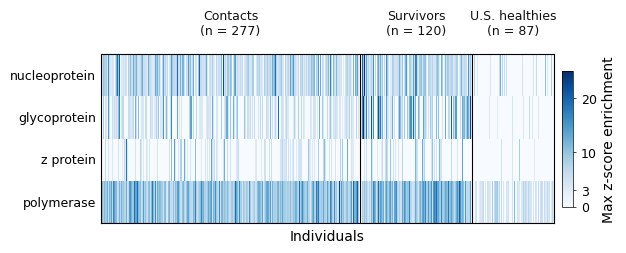

In [88]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from fig_style import apply_style

apply_style()

TEXT_COLOR = "#111111"

# Group sizes / labels (rename to match your study)
groups = [
    ("Contacts",   len(c_cols)),
    ("Survivors",  len(s_cols)),
    ("U.S. healthies", len(hbdb_cols)),
]

fig, ax = plt.subplots(figsize=(7, 2.2))

#clip everything under z score 3 to 0 -> will turn white
plot_data = lassa_max_wide.where(lassa_max_wide >= 3, 0) 

PROTEIN_ORDER = ["nucleoprotein", "glycoprotein", "z protein", "polymerase"]

plot_data = plot_data.loc[PROTEIN_ORDER]

sns.heatmap(
    data=plot_data,
    vmin=0, vmax=25,
    cmap="Blues",
    xticklabels=False,
    ax=ax,
    rasterized=True,
    cbar_kws=dict(
        label="Max z-score enrichment",   # <- your actual metric
        shrink=0.8, aspect=12, pad=0.015,
        ticks=[0, 3, 10, 20],
    ),
)

# Group separators + labels on top
edges = np.cumsum([n for _, n in groups])
starts = np.r_[0, edges[:-1]]

for x in edges[:-1]:
    ax.axvline(x, color="white", linewidth=2)

for (name, n), x0 in zip(groups, starts):
    ax.text(x0 + n / 2, -0.4, f"{name}\n(n = {n})",
            ha="center", va="bottom", fontsize=9, color=TEXT_COLOR)

ax.set_xlabel("Individuals")
ax.set_ylabel("")
ax.tick_params(axis="y", length=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
for x in edges[:-1]:
    ax.axvline(x, color="black", linewidth=0.8)

cbar = ax.collections[0].colorbar
cbar.outline.set_linewidth(0.5)
cbar.ax.tick_params(width=0.5, length=2)


for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)

fig.savefig("./output_figures/Fig_LASV_heatmap.svg",
            bbox_inches="tight", transparent=True)
plt.show()

## 3. Investigate seroprevalence by protein